Sample Dataset:
   Years_of_Experience        Salary
0                    1  33473.713224
1                    2  32893.885591
2                    3  43681.508305
3                    4  55184.238851
4                    5  45626.773002

Simple Linear Regression Results
MAE: 4810.498779986485
MSE: 39810703.506571256
RMSE: 6309.572371133503
R2 Score: 0.9975751668213524
Intercept: 23548.516826342122
Coefficient: 4509.76487752533

Actual vs Predicted:
   Actual Salary  Predicted Salary
0  398853.838254     402368.766538
1  272893.410311     267075.820213
2  347391.164844     343741.823131
3  226241.246333     230997.701193
4  215671.824077     226487.936315


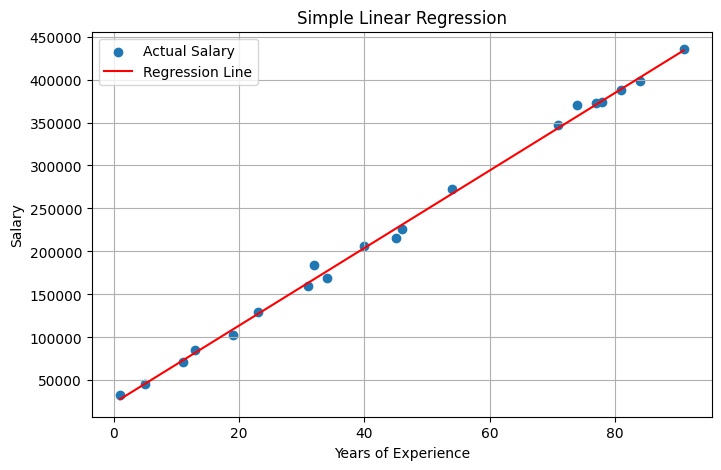

In [1]:

# SIMPLE LINEAR REGRESSION

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 2: Create sample dataset
np.random.seed(42)

experience = np.arange(1, 101)

salary = 25000 + 4500 * experience + np.random.normal(0, 8000, 100)

df = pd.DataFrame({
    "Years_of_Experience": experience,
    "Salary": salary
})

print("Sample Dataset:")
print(df.head())

# Step 3: Separate input and output
X = df[["Years_of_Experience"]]
y = df["Salary"]

# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 5: Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 6: Make predictions
y_pred = model.predict(X_test)

# Step 7: Evaluate the model
print("\nSimple Linear Regression Results")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

# Step 8: Display actual and predicted values
results = pd.DataFrame({
    "Actual Salary": y_test.to_numpy(),
    "Predicted Salary": y_pred
})

print("\nActual vs Predicted:")
print(results.head())

# Step 9: Visualize the results
plt.figure(figsize=(8, 5))

plt.scatter(X_test["Years_of_Experience"], y_test,
            label="Actual Salary")

sorted_indices = np.argsort(X_test["Years_of_Experience"].to_numpy())

plt.plot(
    X_test["Years_of_Experience"].to_numpy()[sorted_indices],
    y_pred[sorted_indices],
    color="red",
    label="Regression Line"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

Sample Dataset:
          X          Y
0 -5.000000  97.483571
1 -4.932886  91.843474
2 -4.865772  93.344069
3 -4.798658  95.327640
4 -4.731544  84.184623

Polynomial Regression Results
MAE: 3.81513173098477
MSE: 21.635722625825167
RMSE: 4.651421570426096
R2 Score: 0.9783505895146395

Actual vs Predicted:
   Actual Value  Predicted Value
0     17.561744         9.152910
1     51.599468        55.445801
2     58.565562        52.345512
3     11.384213        10.349039
4     10.777787         9.762496


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


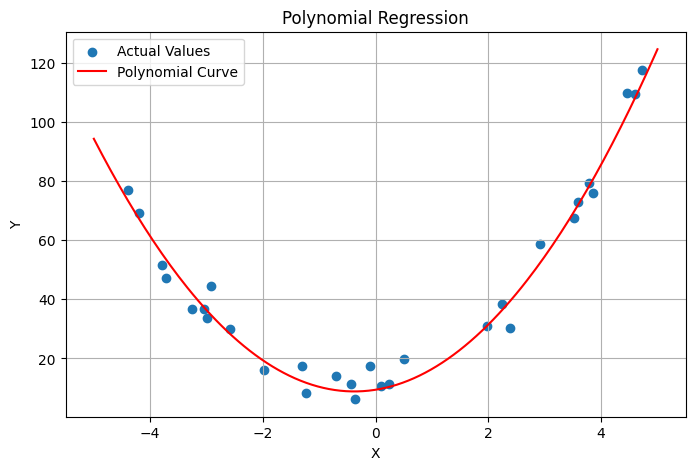

In [3]:

# POLYNOMIAL REGRESSION

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 2: Create sample dataset
np.random.seed(42)

X_values = np.linspace(-5, 5, 150)

Y_values = (
    4 * X_values**2
    + 3 * X_values
    + 10
    + np.random.normal(0, 5, 150)
)

df = pd.DataFrame({
    "X": X_values,
    "Y": Y_values
})

print("Sample Dataset:")
print(df.head())

# Step 3: Separate input and output
X = df[["X"]]
y = df["Y"]

# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 5: Create polynomial regression model
model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Step 6: Train the model
model.fit(X_train, y_train)

# Step 7: Make predictions
y_pred = model.predict(X_test)

# Step 8: Evaluate the model
print("\nPolynomial Regression Results")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Step 9: Display actual and predicted values
results = pd.DataFrame({
    "Actual Value": y_test.to_numpy(),
    "Predicted Value": y_pred
})

print("\nActual vs Predicted:")
print(results.head())

# Step 10: Visualize the polynomial curve
X_curve = np.linspace(-5, 5, 200).reshape(-1, 1)
Y_curve = model.predict(X_curve)

plt.figure(figsize=(8, 5))

plt.scatter(X_test["X"], y_test, label="Actual Values")

plt.plot(
    X_curve.ravel(),
    Y_curve,
    color="red",
    label="Polynomial Curve"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()